## Exercise 2: First look


In [1]:
# Cell 1: Imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

In [2]:
## Load Titanic dataset
df_raw = pd.read_csv("data/titanic.csv")
print(f"Shape of the dataset: {df_raw.shape}")
display(df_raw.head())

Shape of the dataset: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
# Cell 4: Column types and missing values
print("Column types and missing values:")
df_raw.info()

Column types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [4]:
# Cell 5: Summary of the number columns
df_raw.describe().round(2) # .round(2) rounds the numbers to 2 decimal places

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


In [5]:
# Cell 6: Summary of the text columns

print(f"Summary of text columns:\n{df_raw.describe(include='str')}") # include='str' includes only text columns

Summary of text columns:
         sex embarked  class  who deck  embark_town alive
count    891      889    891  891  203          889   891
unique     2        3      3    3    7            3     2
top     male        S  Third  man    C  Southampton    no
freq     577      644    491  537   59          644   549


In [6]:
#  Cell 7: Percentage missing per column

missing_pct = (df_raw.isna().mean() * 100).round(1).sort_values(ascending=False)
missing_pct[missing_pct > 0]

deck           77.2
age            19.9
embarked        0.2
embark_town     0.2
dtype: float64

In [7]:
#  Cell 8: Survival rate

survival_rate = df_raw["survived"].mean()
print(f"Survival rate: {survival_rate:.1%}")   
print(df_raw["survived"].value_counts())

Survival rate: 38.4%
survived
0    549
1    342
Name: count, dtype: int64


In [8]:
# Cell 9: Passengers per class and per port

print(f"Passengers per class:\n{df_raw['class'].value_counts()}")
print(f"Passengers per port:\n{df_raw['embarked'].value_counts(dropna=False)}") # dropna=False includes NaN values in the count

Passengers per class:
class
Third     491
First     216
Second    184
Name: count, dtype: int64
Passengers per port:
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


## Exercise 2 answers
- **Size:** 891 passengers, 15 columns.
- **Missing:** `deck` 77.2%, `age` 19.9%, `embarked` / `embark_town` 0.2% (2 rows). Everything else is complete.
- **Survival rate:** 38.4% (342 of 891).
- **Class:** Third 491, First 216, Second 184. **Port:** Southampton 644, Cherbourg 168, Queenstown 77, unknown 2.
- **Fare is skewed:** mean £32.20 vs median £14.45 (max £512.33), so a few very expensive tickets pull the average up.
- `pclass` is a category stored as a number, so its mean (2.31) is meaningless.
- The mean of a True/False or 0/1 column is the share of `True`/1, which is how `isna().mean()` gives the share missing.


## Exercise 3: Spot the problems

In [9]:
# Part 1: Redundant columns
pd.crosstab(df_raw["pclass"], df_raw["class"])



class,First,Second,Third
pclass,,,
1,216,0,0
2,0,184,0
3,0,0,491


In [10]:
display(pd.crosstab(df_raw["survived"], df_raw["alive"]))
display(pd.crosstab(df_raw["embarked"], df_raw["embark_town"]))

alive,no,yes
survived,,
0,549,0
1,0,342


embark_town,Cherbourg,Queenstown,Southampton
embarked,,,
C,168,0,0
Q,0,77,0
S,0,0,644


In [11]:
# Cell 3: Derived columns

print((df_raw["adult_male"] == (df_raw["who"] == "man")).all())
print((df_raw["alone"] == (df_raw["sibsp"] + df_raw["parch"] == 0)).all())

True
True


## Part 2: Duplicates

In [12]:
# Cell 4 : How many?

print("Duplicated rows:", df_raw.duplicated().sum())
print("Rows involved:  ", df_raw.duplicated(keep=False).sum())

Duplicated rows: 107
Rows involved:   160


In [13]:
# Cell 5: The biggest groups

cols = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
dups = df_raw[df_raw.duplicated(keep=False)]
dups[cols].value_counts(dropna=False).head(3)

survived  pclass  sex   age  sibsp  parch  fare    embarked
0         3       male  NaN  0      0      7.8958  S           13
                                           8.0500  S           12
                                           7.7500  Q            8
Name: count, dtype: int64

In [14]:
# Cell 6: What the duplicates have in common

print(f"Age missing: {dups['age'].isna().mean():.1%}")
print(dups["pclass"].value_counts())

Age missing: 58.1%
pclass
3    125
2     31
1      4
Name: count, dtype: int64


## Part 3: Odd values

In [15]:
# Cell 7: Fares of £0

zero = df_raw[df_raw["fare"] == 0]
print(f"{len(zero)} passengers paid £0: "
      f"{(zero['sex'] == 'male').sum()} men, {zero['alone'].sum()} alone, "
      f"{(zero['embarked'] == 'S').sum()} from Southampton, {zero['survived'].sum()} survived")
print(zero["pclass"].value_counts().sort_index())

15 passengers paid £0: 15 men, 15 alone, 15 from Southampton, 1 survived
pclass
1    5
2    6
3    4
Name: count, dtype: int64


In [16]:
# Cell 8: The highest fares

display(df_raw.nlargest(5, "fare")[["survived", "pclass", "sex", "age", "fare", "embarked"]])
print("99% of fares are below:", df_raw["fare"].quantile(0.99).round(2))

,survived,pclass,sex,age,fare,embarked
258,1,1,female,35.0,512.3292,C
679,1,1,male,36.0,512.3292,C
737,1,1,male,35.0,512.3292,C
27,0,1,male,19.0,263.0000,S
88,1,1,female,23.0,263.0000,S


99% of fares are below: 249.01


In [17]:
# Bonus: Odd ages

print("Babies:", df_raw.loc[df_raw["age"] < 1, "age"].tolist())
print("Ages ending in .5 (over 1):", ((df_raw["age"] % 1 == 0.5) & (df_raw["age"] > 1)).sum())

Babies: [0.83, 0.92, 0.75, 0.75, 0.67, 0.42, 0.83]
Ages ending in .5 (over 1): 18


## Exercise 3 answers
- **Redundant pairs** (crosstabs are diagonal-only): `pclass`/`class`, `survived`/`alive`, `embarked`/`embark_town`. Keep one of each. `alive` would be **data leakage** if it were used to predict `survived`.
- **Derived columns:** `adult_male` = "who is man"; `alone` = sibsp + parch == 0. Keep them as shortcuts.
- **Duplicates:** 107 (160 rows in 53 groups; the biggest is 13 third-class men with no age and the same £7.90 fare). **Keep them:** with no name or ticket ID, identical-looking rows are different people. Deleting them would remove real passengers.
- **£0 fares:** 15 passengers, all men, alone, from Southampton (likely complimentary tickets). Real, not errors.
- **Max fare £512.33:** 3 first-class passengers from Cherbourg on one shared booking. A real outlier; 99% of fares are below £249.
- **Outlier ≠ error:** delete errors, keep real outliers, and use the median when data is skewed.


## Exercise 4: Clean

In [18]:
# Cell 1: Drop the columns you don't need

df = df_raw.drop(columns=["class", "alive", "embark_town", "deck"])
print("df:    ", df.shape)
print("df_raw:", df_raw.shape)
print(list(df.columns))

df:     (891, 11)
df_raw: (891, 15)
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'who', 'adult_male', 'alone']


In [19]:
# Cell 2: Why fill age by class?

print(df.groupby("pclass")["age"].median())
print("Overall median:", df["age"].median())
print(df.loc[df["age"].isna(), "pclass"].value_counts().sort_index())

pclass
1    37.0
2    29.0
3    24.0
Name: age, dtype: float64
Overall median: 28.0
pclass
1     30
2     11
3    136
Name: count, dtype: int64


In [20]:
# Cell 3: transform gives one value per row, not per group

class_median = df.groupby("pclass")["age"].transform("median")
print(class_median.shape)
display(df[["pclass", "age"]].assign(class_median=class_median).head(6))

(891,)


,pclass,age,class_median
0,3,22.0,24.0
1,1,38.0,37.0
2,3,26.0,24.0
3,1,35.0,37.0
4,3,35.0,24.0
5,3,NaN,24.0


In [21]:
# Cell 4: Fill the missing ages

was_missing = df["age"].isna()      # remember which rows were empty
df["age"] = df["age"].fillna(class_median)
print("Missing ages now:", df["age"].isna().sum())
df.loc[was_missing, ["pclass", "age"]].value_counts()

Missing ages now: 0


pclass  age 
3       24.0    136
1       37.0     30
2       29.0     11
Name: count, dtype: int64

In [22]:
# Cell 5: Fill the 2 missing ports

display(df_raw.loc[df_raw["embarked"].isna(), cols])
port = df["embarked"].mode()[0]
print("Most common port:", port)
df["embarked"] = df["embarked"].fillna(port)

,survived,pclass,sex,age,sibsp,parch,fare,embarked
61,1,1,female,38.0,0,0,80.0,NaN
829,1,1,female,62.0,0,0,80.0,NaN


Most common port: S


In [23]:
# Cell 6: Final check

print("Shape:", df.shape)
print("Missing values in df:    ", df.isna().sum().sum())
print("Missing values in df_raw:", df_raw.isna().sum().sum())

Shape: (891, 11)
Missing values in df:     0
Missing values in df_raw: 869


In [24]:
# Cell 7: The side effect of filling

pd.DataFrame({
    "before": df_raw["age"].describe(),
    "after": df["age"].describe(),
}).round(2)

,before,after
count,714.00,891.00
mean,29.70,29.07
std,14.53,13.24
min,0.42,0.42
25%,20.12,22.00
50%,28.00,26.00
75%,38.00,37.00
max,80.00,80.00


## Exercise 4 answers
- **Dropped:** `class`, `alive`, `embark_town` (redundant) and `deck` (77% missing). `drop()` returns a new DataFrame, so `df_raw` is unchanged (891, 15).
- **Age:** filled with the **median of each passenger's class** (1st 37, 2nd 29, 3rd 24) using `groupby().transform("median")`, because first-class passengers were older. 136 of the 177 missing ages were third class.
- **Embarked:** the 2 missing values (two first-class women on the same £80 fare) filled with the mode, `S`.
- **Result:** `df` is (891, 11) with 0 missing values.
- **Side effect:** filling shrinks the spread of age (std 14.53 → 13.24) and moves the median from 28 to 26, so use `df_raw["age"]` when the question is about age itself.


## Exercise 5:

In [25]:
# Cell 1: A helper function, then sex

def survival_by(groups):
    """Number of passengers and survival rate (%) for each group."""
    table = df.groupby(groups, observed=True)["survived"].agg(["count", "mean"])
    table["mean"] = (table["mean"] * 100).round(1)
    return table.rename(columns={"count": "passengers", "mean": "survival_%"})

survival_by("sex")

,passengers,survival_%
sex,,
female,314,74.2
male,577,18.9


In [26]:
# Cell 2: Class

survival_by("pclass")

,passengers,survival_%
pclass,,
1,216,63.0
2,184,47.3
3,491,24.2


In [27]:
# Cell 3: Sex and class together

rates = df.pivot_table(index="sex", columns="pclass", values="survived",
                       aggfunc="mean", margins=True)
(rates * 100).round(1)

pclass,1,2,3,All
sex,,,,
female,96.8,92.1,50.0,74.2
male,36.9,15.7,13.5,18.9
All,63.0,47.3,24.2,38.4


In [28]:
# Cell 4: Age groups with pd.cut

bins = [0, 12, 18, 35, 60, 120]
labels = ["child", "teen", "young adult", "adult", "senior"]
age_group = pd.cut(df_raw["age"], bins=bins, labels=labels)
print(age_group.head(6))
survival_by(age_group)


0    young adult
1          adult
2    young adult
3    young adult
4    young adult
5            NaN
Name: age, dtype: category
Categories (5, str): ['child' < 'teen' < 'young adult' < 'adult' < 'senior']


,passengers,survival_%
age,,
child,69,58.0
teen,70,42.9
young adult,358,38.3
adult,195,40.0
senior,22,22.7


In [29]:
# Cell 5: Why df_raw["age"] and not your filled ages?

real = survival_by(age_group)
filled = survival_by(pd.cut(df["age"], bins=bins, labels=labels))
display(real.join(filled, suffixes=("", "_filled")))
no_age = df_raw.loc[df_raw["age"].isna(), "survived"].mean()
print(f"Survival rate of the 177 passengers with no age: {no_age:.1%}")

,passengers,survival_%,passengers_filled,survival_%_filled
age,,,,
child,69,58.0,69,58.0
teen,70,42.9,70,42.9
young adult,358,38.3,505,34.7
adult,195,40.0,225,40.9
senior,22,22.7,22,22.7


Survival rate of the 177 passengers with no age: 29.4%


In [30]:
# Cell 6: Family size

df["family_size"] = df["sibsp"] + df["parch"] + 1
survival_by("family_size")

,passengers,survival_%
family_size,,
1,537,30.4
2,161,55.3
3,102,57.8
4,29,72.4
5,15,20.0
6,22,13.6
7,12,33.3
8,6,0.0
11,7,0.0


In [31]:
# Cell 7: Group the family sizes

family_type = pd.cut(df["family_size"], bins=[0, 1, 4, 11],
                     labels=["alone", "small (2-4)", "large (5+)"])
survival_by(family_type)

,passengers,survival_%
family_size,,
alone,537,30.4
small (2-4),292,57.9
large (5+),62,16.1


## Exercise 5 answers
1. **Sex:** women 74.2% vs men 18.9%, so women were almost 4 times as likely to survive.
2. **Class:** 1st 63.0%, 2nd 47.3%, 3rd 24.2%. Each class down lowered the odds.
3. **Sex × class:** first-class women 96.8%, third-class women 50.0%, third-class men 13.5%. Sex mattered more than class: a third-class woman (50.0%) did better than a first-class man (36.9%).
4. **Age (real ages only):** children 58.0%, seniors 22.7%; teens, young adults and adults all 38–43%. **Why `df_raw["age"]`:** the 177 filled ages all land on 24, 29 or 37, so "young adult" grows from 358 to 505, and its rate drops from 38.3% to 34.7% because the passengers with no age had only a 29.4% survival rate. Filled values are a guess, so don't use them to answer questions about that column.
5. **Family size:** alone 30.4%, small families (2–4) 57.9%, large families (5+) 16.1%. A family of 4 had the best rate (72.4%), but small groups (29 people or fewer) give noisy rates.


## Exercise 6: Charts

In [32]:
# Exercise 6: Charts

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#f0efec"

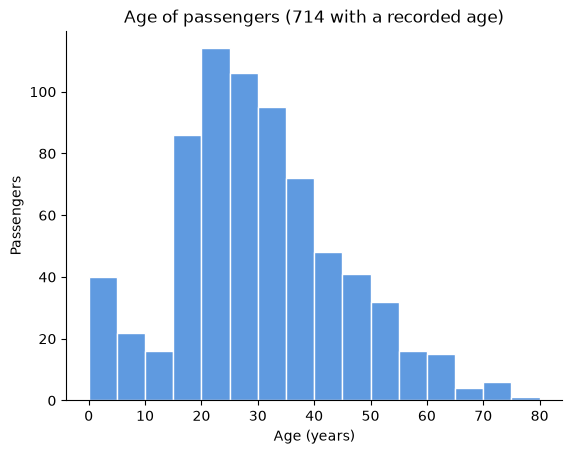

In [33]:
# Cell 2: Age histogram

sns.histplot(df_raw["age"], bins=range(0, 85, 5), color=BLUE, edgecolor="white")
plt.title("Age of passengers (714 with a recorded age)")
plt.xlabel("Age (years)")
plt.ylabel("Passengers")
plt.savefig(output_dir / "age_histogram.png", bbox_inches="tight")
plt.show()

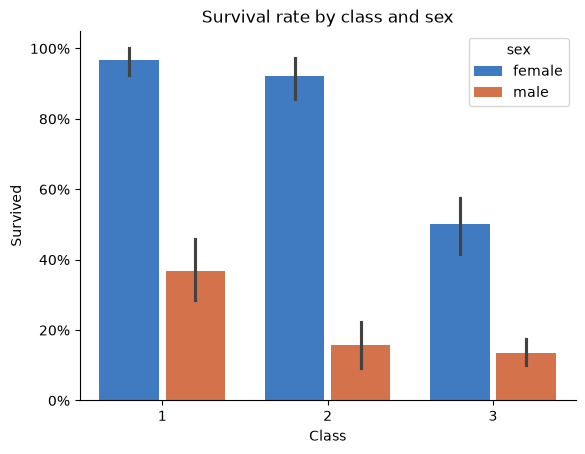

In [34]:
# Cell 3: Survival by class and sex

ax = sns.barplot(data=df, x="pclass", y="survived", hue="sex", palette={"female": BLUE, "male": ORANGE}, gap=0.1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.title("Survival rate by class and sex")
plt.xlabel("Class")
plt.ylabel("Survived")
plt.savefig(output_dir / "survival_by_class_sex.png", bbox_inches="tight")
plt.show()

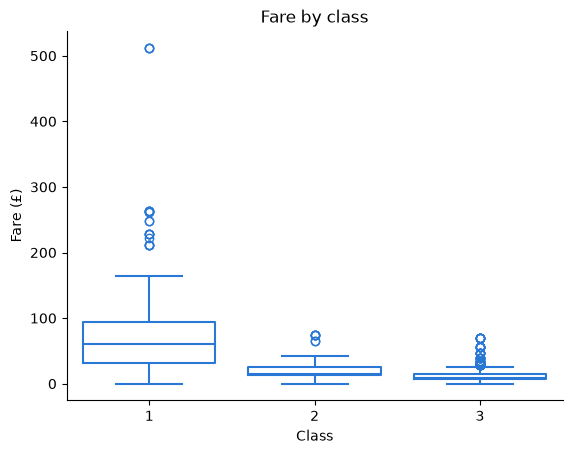

pclass
1    60.2875
2    14.2500
3     8.0500
Name: fare, dtype: float64


In [35]:
# Cell 4: Fare by class (box plot)

sns.boxplot(data=df, x="pclass", y="fare", color=BLUE, fill=False)
plt.title("Fare by class")
plt.xlabel("Class")
plt.ylabel("Fare (£)")
plt.savefig(output_dir / "fare_by_class.png", bbox_inches="tight")
plt.show()
print(df.groupby("pclass")["fare"].median())

In [36]:
# Cell 5: Correlations

df["is_male"] = (df["sex"] == "male").astype(int)
num_cols = ["survived", "is_male", "pclass", "fare", "age", "sibsp", "parch"]
corr = df[num_cols].corr()
corr["survived"].drop("survived").sort_values().round(2)

is_male   -0.54
pclass    -0.34
age       -0.05
sibsp     -0.04
parch      0.08
fare       0.26
Name: survived, dtype: float64

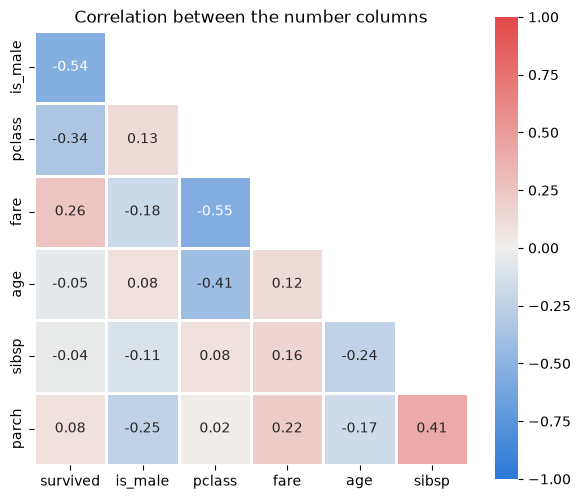

In [37]:
# Cell 6: Correlation heatmap

lower = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(lower, dtype=bool), k=1)
plt.figure(figsize=(7, 6))
sns.heatmap(lower, mask=mask, annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap=sns.blend_palette([BLUE, GRAY, RED], as_cmap=True),
            linewidths=2, linecolor="white", square=True)
plt.title("Correlation between the number columns")
plt.savefig(output_dir / "correlation_heatmap.png", bbox_inches="tight")
plt.show()

## Exercise 6 answers
- **Age** (real ages): about two thirds of passengers were 15–40, the peak is 20–25 (114 people), there's a bump of 40 children aged 0–5, and very few were over 60.
- **Survival by class and sex:** averaging is right here because `survived` is 0/1, so each bar's mean **is** the survival rate (in Task 3 we wanted totals, so `estimator="sum"`). Women beat men in every class; the gap is biggest in 2nd class (92% vs 16%).
- **Fare by class:** medians £60.29 / £14.25 / £8.05. First class has the widest spread and the £512 outliers (one shared booking). Third-class "outliers" are family tickets: fare is per ticket, not per person.
- **Correlation with survived:** `is_male` −0.54, `pclass` −0.34, `fare` +0.26; the rest are near 0.
- **Limits:** correlation only sees straight-line links (family size is 0.02, but Ex 5 shows a strong up-then-down pattern), and it isn't causation (`fare` is tied to `pclass`, −0.55).


## Exercise 7: Findings

In [38]:
# Cell 1: Pull the headline numbers from your analysis

by_sex = survival_by("sex")["survival_%"]
by_class = survival_by("pclass")["survival_%"]
by_age = survival_by(age_group)["survival_%"]
by_family = survival_by(family_type)["survival_%"]

print(f"1. Women vs men:        {by_sex['female']:.0f}% vs {by_sex['male']:.0f}% "
      f"({by_sex['female'] / by_sex['male']:.1f}x)")

print(f"2. 1st vs 3rd class:    {by_class.loc[1]:.0f}% vs {by_class.loc[3]:.0f}% "
      f"({by_class.loc[1] / by_class.loc[3]:.1f}x)")

print(f"3. 3rd-class women {rates.loc['female', 3]:.0%}, 1st-class men "
      f"{rates.loc['male', 1]:.0%}, 3rd-class men {rates.loc['male', 3]:.0%}")

print(f"4. Children vs young adults: {by_age['child']:.0f}% vs {by_age['young adult']:.0f}%")

print(f"5. Alone / small / large family: {by_family['alone']:.0f}% / "
      f"{by_family['small (2-4)']:.0f}% / {by_family['large (5+)']:.0f}%")

print(f"Limitation: {df_raw['age'].isna().mean():.0%} of ages missing "
      f"({df_raw['age'].isna().sum()} of {len(df_raw)})")


1. Women vs men:        74% vs 19% (3.9x)
2. 1st vs 3rd class:    63% vs 24% (2.6x)
3. 3rd-class women 50%, 1st-class men 37%, 3rd-class men 14%
4. Children vs young adults: 58% vs 38%
5. Alone / small / large family: 30% / 58% / 16%
Limitation: 20% of ages missing (177 of 891)


## Exercise 7: Answers

**Who survived the Titanic?** An analysis of 891 passengers.

1. **Sex was the biggest factor:** women were almost four times as likely to survive as men (74% vs 19%).
2. **Class mattered too:** 63% of first-class passengers survived, compared with 24% in third class.
3. **Sex outweighed class:** a third-class woman had better odds (50%) than a first-class man (37%), and third-class men had the worst odds of all (14%).
4. **Children were more likely to be saved:** 58% of children aged 12 and under survived, against 38% of young adults (19–35).
5. **Small families did best:** 58% of people in families of 2–4 survived, nearly twice the rate of people travelling alone (30%), while large families of 5 or more did worst (16%).

**Limitation:** 1 in 5 passengers (177 of 891) has no recorded age, and most of them travelled third class. So the age finding rests on the 714 known ages, and it may not hold for everyone on board.
